# Bagian A: Linear Regression untuk Memprediksi Konsumsi BBM Mobil (Auto MPG)

Mata kuliah Fundamen Sains Data, Tugas Kelompok Linear Regression dan Logistic Regression.

Anggota kelompok:

| Nama | NIM |
|---|---|
| Gusti Surya Aditama | 25523053 |
| Muhammad Lutfi Syarif | 25523021 |
| Naufal Alaam Najib | 25523063 |

Di bagian ini kami memprediksi `mpg` (miles per gallon, jarak tempuh per galon bensin) dari spesifikasi mobil memakai `LinearRegression`. Urutannya mengikuti soal: deskripsi data (A1), eksplorasi (A2), preprocessing (A3), pemilihan fitur (A4), pembagian data (A5), pemodelan (A6), evaluasi (A7), lalu analisis performa (A8).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

## A1. Deskripsi Dataset

Dataset yang dipakai adalah Auto MPG dari UCI Machine Learning Repository (Quinlan, 1993; data aslinya dari StatLib, Carnegie Mellon University). File CSV-nya kami ambil dari repositori `seaborn-data`.

- UCI: <https://archive.ics.uci.edu/dataset/9/auto+mpg>
- CSV: <https://github.com/mwaskom/seaborn-data/blob/master/mpg.csv>

Kami memilih dataset ini karena targetnya angka kontinu, ukurannya tidak terlalu besar (398 baris), dan ada beberapa hal yang bisa dibahas di tugas ini: ada missing value, ada satu kolom kategorikal, dan beberapa fitur saling berkorelasi kuat.

Arti tiap kolom:

| Kolom | Tipe | Arti |
|---|---|---|
| `mpg` | numerik | **target**, jarak tempuh (mil) per galon. Makin besar berarti makin irit |
| `cylinders` | numerik | jumlah silinder mesin |
| `displacement` | numerik | volume mesin (cu. inch) |
| `horsepower` | numerik | tenaga mesin (hp) |
| `weight` | numerik | bobot mobil (lbs) |
| `acceleration` | numerik | waktu 0 ke 60 mph (detik), makin besar berarti makin lambat |
| `model_year` | numerik | tahun model (70 = 1970, dst.) |
| `origin` | kategorikal | asal mobil: `usa`, `europe`, `japan` |
| `name` | teks | nama mobil, hanya pengenal dan tidak dipakai sebagai fitur |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
try:
    df_raw = pd.read_csv(DATA_URL)
except Exception:
    df_raw = pd.read_csv("data/mpg.csv")  # cadangan: salinan lokal di repositori

print(f"Jumlah baris: {df_raw.shape[0]} | Jumlah kolom: {df_raw.shape[1]}")
df_raw.head()

Jumlah baris: 398 | Jumlah kolom: 9


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


Datanya 398 baris dengan 7 fitur (di luar `mpg` dan `name`), jadi sudah memenuhi syarat minimal 200 baris dan 3 fitur. Kolom `horsepower` hanya terisi 392 baris, berarti ada 6 data kosong. Itu kami tangani di A3.

## A2. Eksplorasi dan Visualisasi Data

Sebelum membuat model kami lihat dulu statistik deskriptif dan beberapa grafik.

In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0


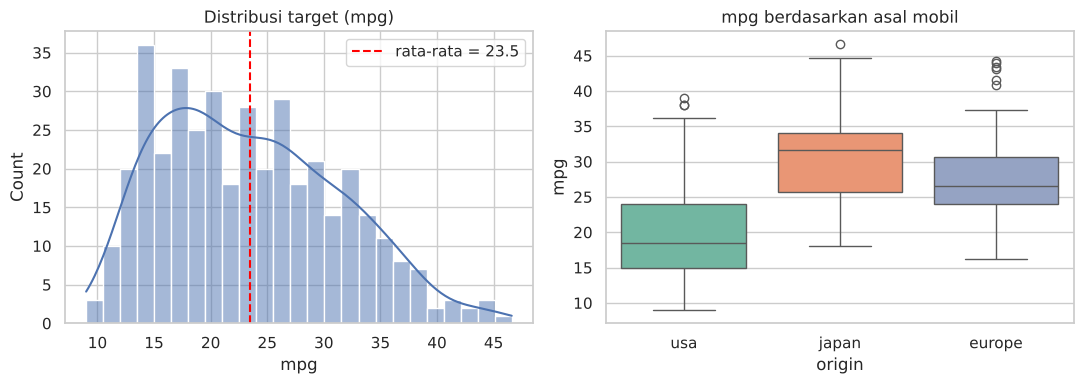

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df_raw["mpg"], bins=25, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(df_raw["mpg"].mean(), color="red", linestyle="--", label=f"rata-rata = {df_raw['mpg'].mean():.1f}")
axes[0].set_title("Distribusi target (mpg)")
axes[0].legend()

sns.boxplot(data=df_raw, x="origin", y="mpg", ax=axes[1], palette="Set2")
axes[1].set_title("mpg berdasarkan asal mobil")

plt.tight_layout()
plt.show()

Temuan dari histogram dan boxplot:

- Distribusi `mpg` agak miring ke kanan. Kebanyakan mobil ada di kisaran 15 sampai 30 mpg, tapi ada ekor panjang ke mobil yang sangat irit (di atas 40 mpg).
- Mobil `usa` rata-rata paling boros, sedangkan `japan` dan `europe` lebih irit. Tapi perbedaan ini bisa saja bercampur dengan ukuran dan bobot mobilnya, jadi belum bisa kami simpulkan bahwa asal negara yang menyebabkan beda konsumsi. Ini kami cek lagi di model.

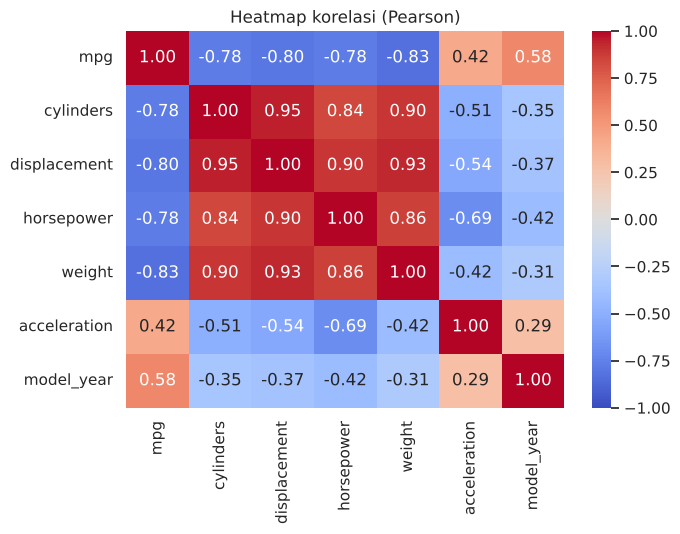

In [6]:
numeric_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]

plt.figure(figsize=(7, 5.5))
sns.heatmap(df_raw[["mpg"] + numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Heatmap korelasi (Pearson)")
plt.tight_layout()
plt.show()

Temuan dari heatmap korelasi:

- `weight` (r sekitar -0.83), `displacement` (-0.81), `horsepower` (-0.78), dan `cylinders` (-0.78) berkorelasi negatif kuat dengan `mpg`. Mobil yang lebih berat atau bermesin besar cenderung lebih boros.
- `model_year` berkorelasi positif sedang (sekitar +0.58). Mobil keluaran lebih baru cenderung lebih irit.
- Masalahnya, `cylinders`, `displacement`, `horsepower`, dan `weight` saling berkorelasi sangat tinggi (misalnya `cylinders` dan `displacement` sekitar 0.95). Ini multikolinearitas, dan nanti membuat koefisien sulit ditafsirkan. Kami tangani di A4.

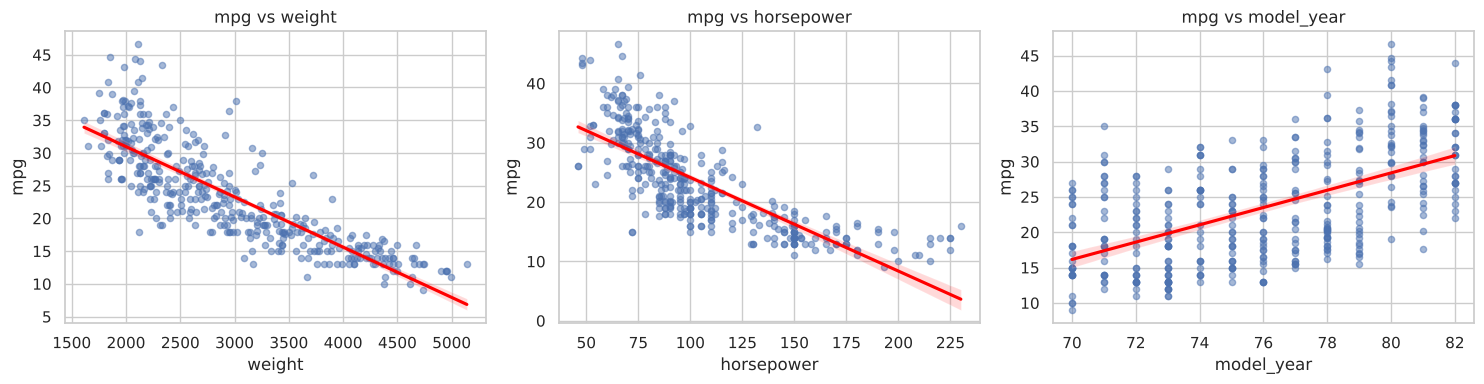

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["weight", "horsepower", "model_year"]):
    sns.regplot(data=df_raw, x=feature, y="mpg", ax=ax, scatter_kws={"alpha": 0.5, "s": 20}, line_kws={"color": "red"})
    ax.set_title(f"mpg vs {feature}")
plt.tight_layout()
plt.show()

Temuan dari scatter plot:

- Hubungan `mpg` dengan `weight` dan `horsepower` terlihat melengkung, bukan lurus. Penurunan mpg tajam di bobot ringan lalu melandai di bobot berat, jadi garis merahnya kurang pas di kedua ujung. Ini yang nanti kami bahas lagi sebagai keterbatasan di A8.
- `model_year` trennya naik dan cukup mendekati lurus.

## A3. Preprocessing

Urutan yang kami pakai: duplikat, missing value, outlier, lalu encoding. Scaling sengaja ditunda sampai setelah data dibagi di A5, supaya tidak terjadi data leakage.

In [8]:
df = df_raw.copy()

# 1) Data duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

# 2) Missing values
print("\nMissing values per kolom:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nBaris dengan horsepower kosong:")
df[df["horsepower"].isna()][["name", "mpg", "horsepower", "weight", "model_year"]]

Jumlah baris duplikat: 0

Missing values per kolom:
horsepower    6
dtype: int64

Baris dengan horsepower kosong:


,name,mpg,horsepower,weight,model_year
32,ford pinto,25.0,NaN,2046,71
126,ford maverick,21.0,NaN,2875,74
330,renault lecar deluxe,40.9,NaN,1835,80
336,ford mustang cobra,23.6,NaN,2905,80
354,renault 18i,34.5,NaN,2320,81
374,amc concord dl,23.0,NaN,3035,82


Duplikat: tidak ada, jadi tidak ada baris yang dibuang.

Missing value: hanya `horsepower` yang kosong, 6 dari 398 baris (sekitar 1.5%). Baris itu kami buang. Jumlahnya sangat kecil, jadi informasi yang hilang tidak banyak. Mengisi dengan median sebenarnya juga bisa, tapi median akan dihitung dari seluruh data sebelum dibagi latih dan uji, sehingga ada sedikit risiko leakage. Membuang 6 baris lebih sederhana.

In [9]:
df = df.dropna(subset=["horsepower"]).drop_duplicates().reset_index(drop=True)
print("Ukuran data setelah pembersihan:", df.shape)

# 3) Outlier dengan aturan IQR (1.5 x IQR)
outlier_summary = []
for column in ["mpg"] + numeric_features:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outlier = ((df[column] < lower) | (df[column] > upper)).sum()
    outlier_summary.append({"kolom": column, "batas_bawah": round(lower, 2), "batas_atas": round(upper, 2), "jumlah_outlier": n_outlier})
pd.DataFrame(outlier_summary)

Ukuran data setelah pembersihan: (392, 9)


,kolom,batas_bawah,batas_atas,jumlah_outlier
0,mpg,-1.00,47.00,0
1,cylinders,-2.00,14.00,0
2,displacement,-151.12,531.88,0
3,horsepower,-1.50,202.50,10
4,weight,141.00,5699.00,0
5,acceleration,8.90,21.90,11
6,model_year,64.00,88.00,0


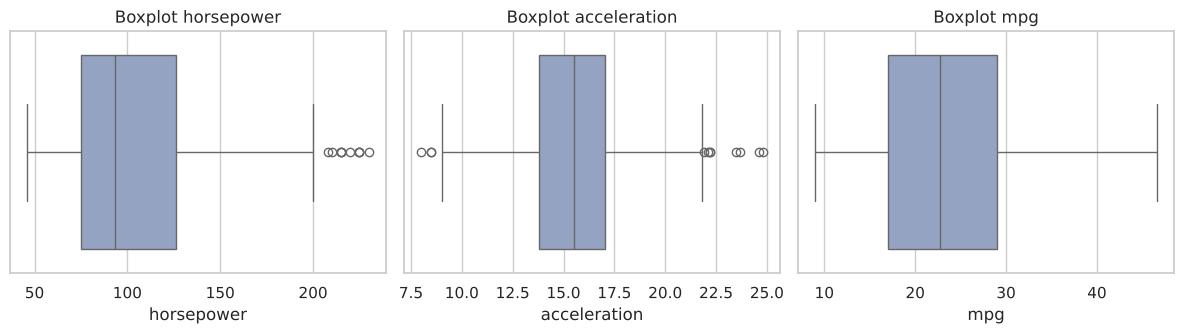

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column in zip(axes, ["horsepower", "acceleration", "mpg"]):
    sns.boxplot(x=df[column], ax=ax, color="#8DA0CB")
    ax.set_title(f"Boxplot {column}")
plt.tight_layout()
plt.show()

Outlier: dengan aturan IQR ada 10 baris `horsepower` dan 11 baris `acceleration` yang ditandai, sedangkan kolom lain tidak ada. Semuanya kami pertahankan karena nilainya masuk akal (mobil bertenaga besar, mobil yang memang lambat) dan kemungkinan besar bukan salah input. Jumlahnya juga kecil, sekitar 2 sampai 3% data.

Risikonya tetap ada: OLS sensitif terhadap titik ekstrem. Karena itu kami periksa lagi lewat residual plot di A7.

In [11]:
# 4) Encoding fitur kategorikal: origin -> one-hot (drop_first untuk menghindari dummy variable trap)
df_encoded = pd.get_dummies(df.drop(columns=["name"]), columns=["origin"], drop_first=True, dtype=float)
print("Kolom hasil encoding:", list(df_encoded.columns))
df_encoded.head()

Kolom hasil encoding: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_japan', 'origin_usa']


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
0,18.0,8,307.0,130.0,3504,12.0,70,0.0,1.0
1,15.0,8,350.0,165.0,3693,11.5,70,0.0,1.0
2,18.0,8,318.0,150.0,3436,11.0,70,0.0,1.0
3,16.0,8,304.0,150.0,3433,12.0,70,0.0,1.0
4,17.0,8,302.0,140.0,3449,10.5,70,0.0,1.0


Encoding: `origin` kategori nominal (tidak ada urutan), jadi kami pakai one-hot encoding. Dengan `drop_first=True` kategori `europe` jadi acuan, supaya tidak kena dummy variable trap. Kolom `name` dibuang karena hampir unik di setiap baris dan tidak bisa dipakai memprediksi mobil baru.

Scaling dilakukan di A5 dengan `StandardScaler` yang hanya di-fit pada data latih. Untuk OLS, scaling tidak mengubah prediksi, tapi membuat koefisien antar fitur bisa dibandingkan di A6.

## A4. Pemilihan Fitur

Kami memakai tiga alat: korelasi dengan target, skor `SelectKBest` (uji-F), dan VIF (Variance Inflation Factor) untuk melihat multikolinearitas. Patokan umumnya, VIF di atas 10 berarti multikolinearitasnya serius.

In [12]:
feature_matrix = df_encoded.drop(columns=["mpg"])
target = df_encoded["mpg"]

# (1) + (2) Korelasi dan SelectKBest (uji F)
selector = SelectKBest(score_func=f_regression, k="all").fit(feature_matrix, target)
ranking = pd.DataFrame({
    "korelasi_dgn_mpg": feature_matrix.corrwith(target).round(3),
    "F_score": selector.scores_.round(1),
    "p_value": selector.pvalues_.round(4),
}).sort_values("F_score", ascending=False)
ranking

,korelasi_dgn_mpg,F_score,p_value
weight,-0.832,878.8,0.0
displacement,-0.805,718.7,0.0
horsepower,-0.778,599.7,0.0
cylinders,-0.778,596.6,0.0
model_year,0.581,198.3,0.0
origin_usa,-0.565,183.0,0.0
origin_japan,0.451,99.8,0.0
acceleration,0.423,85.2,0.0


In [13]:
def compute_vif(features: pd.DataFrame) -> pd.Series:
    with_constant = add_constant(features)
    vif_values = [variance_inflation_factor(with_constant.values, i) for i in range(1, with_constant.shape[1])]
    return pd.Series(vif_values, index=features.columns).round(1).sort_values(ascending=False)

print("VIF sebelum seleksi:")
compute_vif(feature_matrix)

VIF sebelum seleksi:


displacement    22.9
weight          11.1
cylinders       10.7
horsepower      10.0
origin_usa       2.7
acceleration     2.6
origin_japan     1.8
model_year       1.3
dtype: float64

Semua fitur punya hubungan signifikan dengan `mpg` (p < 0.05), jadi tidak ada yang bisa dibuang hanya karena tidak berhubungan dengan target. Yang jadi masalah adalah VIF: `displacement` 22.9, `weight` 11.1, `cylinders` 10.7, dan `horsepower` 10.0.

Keputusan kami, `displacement` dan `cylinders` dibuang. Keduanya paling redundan (korelasi satu sama lain sekitar 0.95) dan informasinya sudah terwakili `weight` dan `horsepower`. Fitur yang dipertahankan adalah `weight` (korelasi paling tinggi dengan target), `horsepower`, `acceleration`, `model_year`, `origin_japan`, dan `origin_usa`.

In [14]:
dropped_features = ["displacement", "cylinders"]
selected_features = feature_matrix.drop(columns=dropped_features)

print("Fitur dipertahankan:", list(selected_features.columns))
print("\nVIF setelah seleksi:")
compute_vif(selected_features)

Fitur dipertahankan: ['horsepower', 'weight', 'acceleration', 'model_year', 'origin_japan', 'origin_usa']

VIF setelah seleksi:


horsepower      9.0
weight          6.4
acceleration    2.5
origin_usa      2.2
origin_japan    1.8
model_year      1.3
dtype: float64

Setelah seleksi VIF turun: `horsepower` 9.0, `weight` 6.4, dan fitur lain di bawah 3. `horsepower` masih agak tinggi (meski di bawah 10), jadi koefisiennya perlu ditafsirkan hati-hati di A6.

## A5. Pembagian Data

Data dibagi 80% untuk latih dan 20% untuk uji dengan `random_state=42` supaya hasilnya bisa diulang. Setelah itu `StandardScaler` di-fit hanya pada data latih, baru diterapkan ke data uji.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    selected_features, target, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Data latih: {X_train.shape[0]} baris | Data uji: {X_test.shape[0]} baris")

scaler = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

Data latih: 313 baris | Data uji: 79 baris


## A6. Pemodelan

In [16]:
model = LinearRegression().fit(X_train_scaled, y_train)

# Koefisien pada fitur ter-standardisasi (untuk membandingkan pengaruh antar fitur)
coef_scaled = pd.Series(model.coef_, index=X_train.columns)
# Koefisien dalam satuan asli (untuk interpretasi praktis): koefisien_asli = koef_scaled / std_fitur
coef_original = pd.Series(model.coef_ / scaler.scale_, index=X_train.columns)
intercept_original = model.intercept_ - np.sum(model.coef_ * scaler.mean_ / scaler.scale_)

coef_table = pd.DataFrame({"koefisien_standardisasi": coef_scaled.round(3), "koefisien_satuan_asli": coef_original.round(4)})
coef_table = coef_table.reindex(coef_scaled.abs().sort_values(ascending=False).index)
print(f"Intercept (fitur ter-standardisasi) : {model.intercept_:.3f}  -> sama dengan rata-rata mpg data latih ({y_train.mean():.3f})")
print(f"Intercept (satuan asli)             : {intercept_original:.3f}")
coef_table

Intercept (fitur ter-standardisasi) : 23.599  -> sama dengan rata-rata mpg data latih (23.599)
Intercept (satuan asli)             : -16.612


,koefisien_standardisasi,koefisien_satuan_asli
weight,-4.627,-0.0055
model_year,2.809,0.7749
origin_usa,-1.083,-2.2638
horsepower,-0.420,-0.0110
origin_japan,0.184,0.4597
acceleration,0.022,0.0080


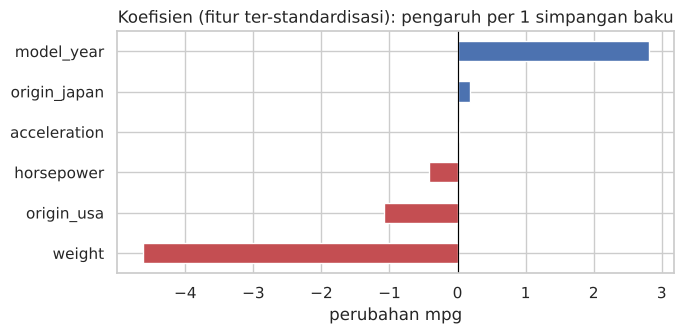

In [17]:
coef_scaled.sort_values().plot(kind="barh", color=["#C44E52" if v < 0 else "#4C72B0" for v in coef_scaled.sort_values()], figsize=(7, 3.5))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Koefisien (fitur ter-standardisasi): pengaruh per 1 simpangan baku")
plt.xlabel("perubahan mpg")
plt.tight_layout()
plt.show()

Cara membaca koefisien: setiap koefisien adalah perubahan `mpg` ketika fitur itu naik satu satuan, dengan fitur lain dianggap tetap.

- `weight` (-0.0055 per lbs, atau sekitar -5.5 mpg tiap tambah 1000 lbs) adalah pengaruh terbesar. Pada skala standar, naik satu simpangan baku bobot menurunkan mpg sekitar 4.6.
- `model_year` (+0.77 per tahun): mobil yang satu tahun lebih baru diprediksi sekitar 0.77 mpg lebih irit.
- `origin_usa` (-2.26) dan `origin_japan` (+0.46) dibandingkan dengan `europe`. Dengan bobot, tenaga, dan tahun yang sama, mobil Amerika diprediksi sekitar 2.3 mpg lebih boros daripada mobil Eropa, sedangkan efek Jepang kecil. Ini data observasi, jadi tidak bisa dibaca sebagai sebab-akibat.
- `horsepower` (-0.011) dan `acceleration` (+0.008) hampir nol. Ini tidak berarti tenaga mesin tidak berpengaruh ke konsumsi BBM. Pengaruhnya kemungkinan sudah diambil oleh `weight` yang berkorelasi kuat dengannya (multikolinearitas).
- Intercept pada skala standar (23.6) sama dengan rata-rata `mpg` data latih. Pada satuan asli intercept-nya sekitar -16.6, dan angka ini tidak punya arti fisik karena tidak ada mobil yang semua fiturnya bernilai 0.

## A7. Evaluasi

Metrik dihitung di data latih dan data uji. Setelah itu ada grafik aktual vs prediksi, residual plot, cross-validation, dan satu eksperimen tambahan dengan `log(mpg)`.

In [18]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

pred_train = model.predict(X_train_scaled)
pred_test = model.predict(X_test_scaled)

metrics_table = pd.DataFrame({"Data latih": regression_metrics(y_train, pred_train), "Data uji": regression_metrics(y_test, pred_test)}).T.round(3)
metrics_table

,MAE,MSE,RMSE,R2
Data latih,2.53,11.006,3.318,0.826
Data uji,2.51,11.183,3.344,0.781


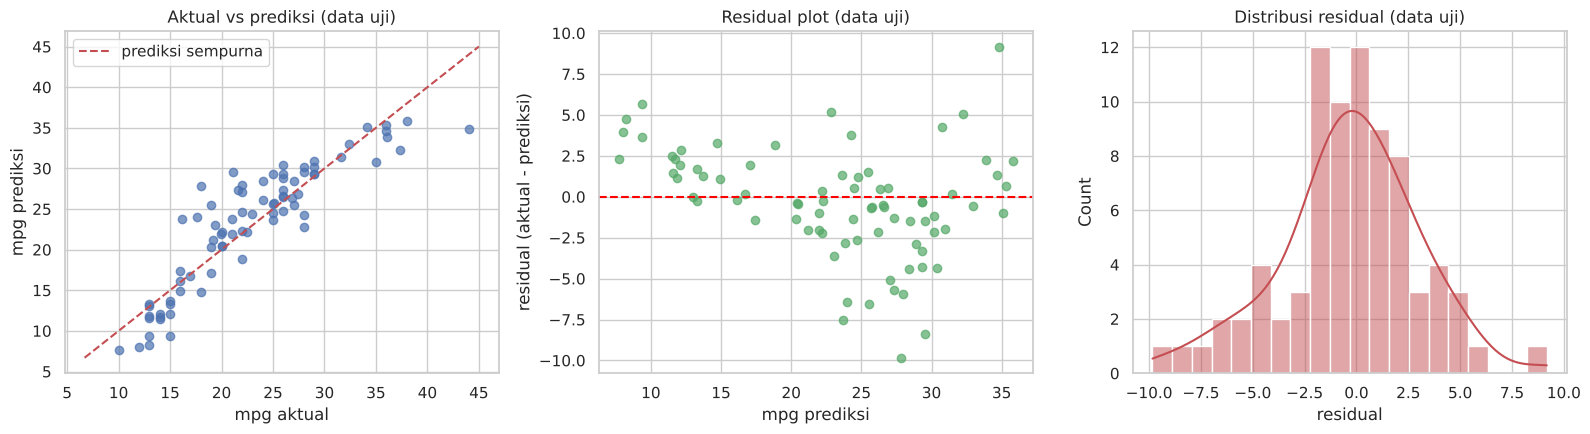

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) Aktual vs prediksi pada data uji
axes[0].scatter(y_test, pred_test, alpha=0.7, color="#4C72B0")
limits = [min(y_test.min(), pred_test.min()) - 1, max(y_test.max(), pred_test.max()) + 1]
axes[0].plot(limits, limits, "r--", label="prediksi sempurna")
axes[0].set(xlabel="mpg aktual", ylabel="mpg prediksi", title="Aktual vs prediksi (data uji)")
axes[0].legend()

# (b) Residual vs prediksi
residual_test = y_test - pred_test
axes[1].scatter(pred_test, residual_test, alpha=0.7, color="#55A868")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="mpg prediksi", ylabel="residual (aktual - prediksi)", title="Residual plot (data uji)")

# (c) Distribusi residual
sns.histplot(residual_test, bins=20, kde=True, ax=axes[2], color="#C44E52")
axes[2].set(xlabel="residual", title="Distribusi residual (data uji)")

plt.tight_layout()
plt.show()

In [20]:
# Validasi tambahan: 5-fold cross-validation (dengan shuffle) supaya hasil tidak bergantung pada satu pembagian saja
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_pipeline = make_pipeline(StandardScaler(), LinearRegression())
cv_r2 = cross_val_score(cv_pipeline, selected_features, target, cv=cv, scoring="r2")
print("R2 per fold :", cv_r2.round(3))
print(f"R2 rata-rata: {cv_r2.mean():.3f} (+/- {cv_r2.std():.3f})")

R2 per fold : [0.781 0.824 0.783 0.823 0.835]
R2 rata-rata: 0.809 (+/- 0.023)


In [21]:
# Eksperimen tambahan: karena hubungan mpg-weight melengkung, coba transformasi log pada target
model_log = LinearRegression().fit(X_train_scaled, np.log(y_train))
pred_test_log = np.exp(model_log.predict(X_test_scaled))  # kembalikan ke skala mpg

comparison = pd.DataFrame({
    "Model dasar (mpg)": regression_metrics(y_test, pred_test),
    "Model log(mpg)": regression_metrics(y_test, pred_test_log),
}).T.round(3)
comparison

,MAE,MSE,RMSE,R2
Model dasar (mpg),2.51,11.183,3.344,0.781
Model log(mpg),2.00,7.501,2.739,0.853


## A8. Analisis Performa

Seberapa bagus modelnya? Lumayan, tapi belum presisi. Di data uji R² nya sekitar 0.78, jadi model bisa menjelaskan kira-kira 78% variasi `mpg`. Rata-rata tebakannya meleset sekitar 2.5 mpg (MAE) dan RMSE-nya sekitar 3.3 mpg. Kalau dibandingkan dengan rata-rata `mpg` yang sekitar 23.5, meleset sekitar 10 sampai 11%. Untuk model linear biasa dengan 6 fitur, menurut kami ini sudah oke.

Soal overfitting, kelihatannya aman. Metrik latih dan ujinya mirip: R² 0.83 vs 0.78, MAE 2.53 vs 2.51, RMSE 3.32 vs 3.34. Kalau overfitting, hasil di data uji harusnya jauh lebih jelek dari data latih, dan ini tidak begitu. Wajar juga sih, modelnya cuma 6 fitur dan data latihnya 313 baris. MAE uji yang malah sedikit lebih kecil dari MAE latih kami anggap kebetulan saja, karena data ujinya cuma 79 baris. Yang lebih kami curigai justru underfitting ringan: R² di data latih sendiri baru 0.83, dan residual plotnya melengkung, artinya ada pola yang tidak ketangkap garis lurus. Cross-validation 5-fold memberi R² rata-rata 0.81, jadi angka 0.78 dari satu kali split sebaiknya dianggap perkiraan saja.

Fitur yang paling berpengaruh adalah `weight` (koefisien standar sekitar -4.6), lalu `model_year` (sekitar +2.8), lalu `origin_usa` (sekitar -1.1). `horsepower`, `acceleration`, dan `origin_japan` kelihatan kecil pengaruhnya di model ini, kemungkinan sebagian karena saling berkorelasi dengan fitur lain.

Keterbatasannya:

1. Hubungannya tidak lurus. Di residual plot, model terlalu pesimis untuk mobil yang prediksinya di bawah 15 mpg (residual positif) dan terlalu optimis di kisaran prediksi 22 sampai 30 mpg (residual negatif). Mobil yang sangat irit juga diremehkan (aktual sekitar 44 mpg, diprediksi sekitar 35). Waktu kami coba `log(mpg)`, R² uji naik dari 0.78 ke 0.85 dan MAE turun ke sekitar 2.0, jadi bentuk linear biasa memang bukan yang paling pas. Polinomial atau model pohon mungkin layak dicoba.
2. `horsepower` dan `weight` masih saling berkorelasi, jadi koefisien masing-masing kurang stabil dan tidak bisa dibaca sebagai efek yang berdiri sendiri.
3. Datanya kecil dan lama (398 mobil, tahun 1970 sampai 1982). Untuk mobil sekarang, misalnya hybrid atau EV, prediksinya sudah di luar jangkauan data.
4. Sebaran residual kelihatannya melebar di prediksi menengah sampai tinggi, kemungkinan heteroskedastisitas ringan. Ini cuma kami lihat dari plot dan belum diuji formal, jadi asumsi OLS mungkin tidak sepenuhnya terpenuhi.
5. Satu kali split 80:20 di data sekecil ini hasilnya gampang berubah-ubah, makanya kami tambah cross-validation.

Kesimpulannya, model ini cukup untuk melihat arah dan seberapa besar pengaruh bobot dan tahun model terhadap konsumsi BBM, dan tidak overfitting. Tapi masih bisa diperbaiki, terutama soal hubungan yang tidak lurus.